# Notebook 04 — Klasterisasi Tahap 2: K-Means++ dan Elbow Method per Rayon

**Judul Penelitian:** Penentuan Lokasi Rumah Pompa Air Pengendali Banjir Menggunakan Klasterisasi DBSCAN dan K-Means (Studi Kasus: Kota Surabaya)

## Tujuan Notebook Ini
1. Memuat dataset hasil Tahap 3 (`saluran_dbscan_utm49s.gpkg`) dan memastikan input K-Means per rayon adalah **gabungan seluruh titik Non-Noise (`Core + Border`)** dalam masing-masing rayon (**21.108 titik total**, bukan per label klaster DBSCAN).
2. Memastikan **164 titik Noise** tidak dilatih ke K-Means, tetapi tetap dipertahankan di dataset keluaran dengan label `-1` / `"Noise"` untuk visualisasi.
3. Menguji rentang **$K = 2$ sampai $10$** per rayon menggunakan `KMeans(init="k-means++", n_init=20, random_state=42)` pada koordinat proyeksi **`easting` (`X1`)** dan **`northing` (`X2`)** (`EPSG:32749`).
4. Menghitung **WCSS (inertia)** serta persentase penurunannya untuk tiap $K$, memvisualisasikan grafik **Elbow Method** 7 rayon, dan menentukan $K$ terpilih per rayon menggunakan `kneed.KneeLocator(curve="convex", direction="decreasing")` beserta pemeriksaan keambiguan siku (*elbow margin*).
5. Menghasilkan label subcluster, koordinat **centroid kandidat awal** dalam UTM 49S (`easting`, `northing`) sekaligus proyeksi baliknya ke WGS84 (`longitude`, `latitude`), serta menyimpan seluruh artefak Tahap 4.

## 1. Setup Path, Import Modul `src/clustering.py`, dan Memuat Hasil Tahap 3

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.clustering import (
    DEFAULT_K_RANGE,
    DEFAULT_KMEANS_N_INIT,
    DEFAULT_RANDOM_STATE,
    run_kmeans_all_rayons,
    save_kmeans_outputs,
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 120

gdf_dbscan = gpd.read_file(PROCESSED_DIR / "saluran_dbscan_utm49s.gpkg")
gdf_rayon = gpd.read_file(PROCESSED_DIR / "rayon_pematusan_utm49s.gpkg").sort_values("id_rayon").reset_index(drop=True)

print(f"Total titik dari Tahap 3    : {len(gdf_dbscan):,} (CRS: {gdf_dbscan.crs})")
print(f"  - Non-Noise (Core+Border) : {int(gdf_dbscan['is_non_noise'].sum()):,}  --> INPUT K-Means per rayon")
print(f"  - Noise (tidak dilatih)   : {int((~gdf_dbscan['is_non_noise']).sum()):,}  --> TETAP DISIMPAN untuk visualisasi")
print(f"Rentang uji K               : {list(DEFAULT_K_RANGE)}")
print(f"Konfigurasi K-Means++       : init='k-means++', n_init={DEFAULT_KMEANS_N_INIT}, random_state={DEFAULT_RANDOM_STATE}")

Total titik dari Tahap 3    : 21,272 (CRS: EPSG:32749)
  - Non-Noise (Core+Border) : 21,108  --> INPUT K-Means per rayon
  - Noise (tidak dilatih)   : 164  --> TETAP DISIMPAN untuk visualisasi
Rentang uji K               : [2, 3, 4, 5, 6, 7, 8, 9, 10]
Konfigurasi K-Means++       : init='k-means++', n_init=20, random_state=42


## 2. Verifikasi Prasyarat Input Non-Noise per Rayon
Sebelum menjalankan K-Means untuk $K = 2 \dots 10$, kita memverifikasi bahwa setiap rayon memiliki jumlah titik Non-Noise (gabungan Core + Border) dan jumlah koordinat unik yang mencukupi ($\ge 10$).

In [2]:
cek_rows = []
for rid, rname in gdf_rayon[["id_rayon", "nama_rayon"]].itertuples(index=False):
    sub = gdf_dbscan[gdf_dbscan["nama_rayon"] == rname]
    sub_nn = sub[sub["is_non_noise"]]
    n_unique_xy = sub_nn[["easting", "northing"]].drop_duplicates().shape[0]
    cek_rows.append({
        "id_rayon": rid,
        "nama_rayon": rname,
        "core": int((sub["dbscan_role"] == "Core").sum()),
        "border": int((sub["dbscan_role"] == "Border").sum()),
        "non_noise_input_kmeans": len(sub_nn),
        "koordinat_unik_non_noise": n_unique_xy,
        "noise_disimpan": int((sub["dbscan_role"] == "Noise").sum()),
        "layak_uji_k2_k10": n_unique_xy >= max(DEFAULT_K_RANGE),
    })
display(pd.DataFrame(cek_rows))

,id_rayon,nama_rayon,core,border,non_noise_input_kmeans,koordinat_unik_non_noise,noise_disimpan,layak_uji_k2_k10
0,RYN-01,Rayon Benowo,1136,11,1147,1147,28,True
1,RYN-02,Rayon Tandes,2603,12,2615,2615,22,True
2,RYN-03,Rayon Wiyung,1099,8,1107,1107,16,True
3,RYN-04,Rayon Jambangan,2527,17,2544,2544,12,True
4,RYN-05,Rayon Rungkut,2094,13,2107,2107,13,True
5,RYN-06,Rayon Genteng,3642,49,3691,3691,27,True
6,RYN-07,Rayon Gubeng,7828,69,7897,7897,46,True


## 3. Eksekusi Elbow Method (`K = 2..10`) dan K-Means++ untuk Seluruh 7 Rayon
Kita memanggil `run_kmeans_all_rayons()` yang melakukan secara terpisah untuk tiap rayon:
1. Menghitung WCSS (`inertia_`) untuk $K = 2, 3, \dots, 10$ pada gabungan titik Core + Border.
2. Mendeteksi titik siku (*elbow*) menggunakan `KneeLocator(S=1.0, curve="convex", direction="decreasing", online=False)` dan mengecek *margin* terhadap kandidat $K$ kedua terbaik (`runner_up_k`).
3. Menjalankan K-Means++ dengan $K$ terpilih, menomori ulang subcluster secara deterministik (Barat → Timur), dan memproyeksikan balik centroid dari UTM 49S ke WGS84 (`longitude`, `latitude`).

In [3]:
gdf_kmeans, gdf_centroids, df_elbow_all, df_kmeans_summary = run_kmeans_all_rayons(
    gdf_dbscan=gdf_dbscan,
    k_values=DEFAULT_K_RANGE,
    n_init=DEFAULT_KMEANS_N_INIT,
    random_state=DEFAULT_RANDOM_STATE,
    sensitivity=1.0,
)

print("=== RINGKASAN HASIL ELBOW METHOD & K-MEANS++ PER RAYON ===")
display(df_kmeans_summary)

print("\n=== TABEL WCSS (DALAM 10^9 m^2) UNTUK K = 2..10 PER RAYON ===")
pivot_wcss = df_elbow_all.pivot(index="nama_rayon", columns="k", values="wcss_1e9_m2")
pivot_wcss = pivot_wcss.loc[gdf_rayon["nama_rayon"].tolist()]
display(pivot_wcss)

print("\n=== TABEL PERSENTASE PENURUNAN WCSS RELATIF (% DARI K-1 KE K) ===")
pivot_drop = df_elbow_all.pivot(index="nama_rayon", columns="k", values="penurunan_relatif_pct")
pivot_drop = pivot_drop.loc[gdf_rayon["nama_rayon"].tolist()]
display(pivot_drop)

=== RINGKASAN HASIL ELBOW METHOD & K-MEANS++ PER RAYON ===


,id_rayon,nama_rayon,jumlah_total_titik,jumlah_non_noise_input,jumlah_noise_tidak_dilatih,k_kneedle,runner_up_k,kneedle_margin,k_digunakan,sumber_k,wcss_terpilih_1e9_m2,penurunan_wcss_dari_k2_pct,min_anggota_subcluster,max_anggota_subcluster,rerata_anggota_subcluster,status_diagnostik_elbow
0,RYN-01,Rayon Benowo,1175,1147,28,5,6.0,0.0233,5,Elbow + Kneedle (S=1.0),0.4743,62.87,40,370,229.4,Wajar (Tegas)
1,RYN-02,Rayon Tandes,2637,2615,22,4,5.0,0.0214,4,Elbow + Kneedle (S=1.0),2.2438,54.72,173,1340,653.8,Wajar (Tegas)
2,RYN-03,Rayon Wiyung,1123,1107,16,5,6.0,0.0094,5,Elbow + Kneedle (S=1.0),0.4927,68.54,4,394,221.4,PERLU CEK: Selisih kurva Kneedle tipis antara ...
3,RYN-04,Rayon Jambangan,2556,2544,12,5,4.0,0.0180,5,Elbow + Kneedle (S=1.0),1.6526,63.65,217,776,508.8,PERLU CEK: Selisih kurva Kneedle tipis antara ...
4,RYN-05,Rayon Rungkut,2120,2107,13,4,5.0,0.0079,4,Elbow + Kneedle (S=1.0),1.9842,60.49,398,620,526.8,PERLU CEK: Selisih kurva Kneedle tipis antara ...
5,RYN-06,Rayon Genteng,3718,3691,27,4,5.0,0.0082,4,Elbow + Kneedle (S=1.0),3.3706,52.53,743,1056,922.8,PERLU CEK: Selisih kurva Kneedle tipis antara ...
6,RYN-07,Rayon Gubeng,7943,7897,46,4,5.0,0.0057,4,Elbow + Kneedle (S=1.0),16.1340,48.72,1416,2650,1974.2,PERLU CEK: Selisih kurva Kneedle tipis antara ...
7,TOTAL,Seluruh Kota Surabaya (7 Rayon),21272,21108,164,31,NaN,NaN,31,Total Centroid Kandidat,26.3522,NaN,4,2650,680.9,Ringkasan Total



=== TABEL WCSS (DALAM 10^9 m^2) UNTUK K = 2..10 PER RAYON ===


k,2,3,4,5,6,7,8,9,10
nama_rayon,,,,,,,,,
Rayon Benowo,1.2773,0.8733,0.6641,0.4743,0.3584,0.2709,0.2075,0.1693,0.1375
Rayon Tandes,4.9557,2.9367,2.2438,1.8071,1.4484,1.2204,1.0341,0.8746,0.7378
Rayon Wiyung,1.5658,0.9966,0.7102,0.4927,0.3317,0.2812,0.2377,0.2041,0.1734
Rayon Jambangan,4.5460,2.8820,2.2021,1.6526,1.2650,1.0701,0.9248,0.7861,0.7045
Rayon Rungkut,5.0218,3.0230,1.9842,1.4667,1.1859,0.9817,0.8062,0.7035,0.6039
Rayon Genteng,7.1012,4.4239,3.3706,2.6845,2.0980,1.7916,1.5290,1.3637,1.2271
Rayon Gubeng,31.4641,22.6707,16.1340,13.0797,10.6490,8.7873,7.5634,6.6854,5.8592



=== TABEL PERSENTASE PENURUNAN WCSS RELATIF (% DARI K-1 KE K) ===


k,2,3,4,5,6,7,8,9,10
nama_rayon,,,,,,,,,
Rayon Benowo,NaN,31.63,23.96,28.58,24.44,24.41,23.40,18.41,18.80
Rayon Tandes,NaN,40.74,23.59,19.47,19.85,15.74,15.26,15.43,15.64
Rayon Wiyung,NaN,36.35,28.74,30.63,32.67,15.22,15.46,14.17,15.05
Rayon Jambangan,NaN,36.60,23.59,24.95,23.45,15.41,13.57,15.00,10.38
Rayon Rungkut,NaN,39.80,34.36,26.08,19.15,17.22,17.87,12.74,14.17
Rayon Genteng,NaN,37.70,23.81,20.35,21.85,14.60,14.66,10.81,10.02
Rayon Gubeng,NaN,27.95,28.83,18.93,18.58,17.48,13.93,11.61,12.36


## 4. Daftar Lengkap Centroid Kandidat Awal Hasil K-Means++
Setiap centroid direpresentasikan dengan `centroid_id` (`RYN-xx-Cyy`), koordinat proyeksi **`easting` / `northing` (meter, EPSG:32749)**, proyeksi balik **`longitude` / `latitude` (derajat, EPSG:4326)**, jumlah titik saluran anggota, komposisi hierarki (`SP/SS/ST/SL`), serta jarak rata-rata dan maksimum anggota ke centroid.

In [4]:
print(f"Total centroid kandidat awal terbentuk di 7 rayon: {len(gdf_centroids)} centroid")
cols_cen = [
    "centroid_id", "nama_rayon", "kmeans_cluster", "easting", "northing",
    "longitude", "latitude", "jumlah_titik", "persen_non_noise_rayon",
    "n_sp", "n_ss", "n_st", "n_sl", "jarak_rerata_ke_centroid_m", "jarak_maks_ke_centroid_m"
]
display(gdf_centroids[cols_cen])

Total centroid kandidat awal terbentuk di 7 rayon: 31 centroid


,centroid_id,nama_rayon,kmeans_cluster,easting,northing,longitude,latitude,jumlah_titik,persen_non_noise_rayon,n_sp,n_ss,n_st,n_sl,jarak_rerata_ke_centroid_m,jarak_maks_ke_centroid_m
0,RYN-01-C01,Rayon Benowo,1,676625.28,9200956.27,112.599707,-7.226009,40,3.49,0,0,1,39,435.68,1111.76
1,RYN-01-C02,Rayon Benowo,2,678182.74,9199269.04,112.613863,-7.241216,359,31.30,0,3,18,338,566.34,1212.64
2,RYN-01-C03,Rayon Benowo,3,680668.65,9195381.73,112.636500,-7.276285,68,5.93,0,0,3,65,715.76,1070.89
3,RYN-01-C04,Rayon Benowo,4,681009.39,9197970.60,112.639501,-7.252865,310,27.03,0,1,11,298,383.04,869.20
4,RYN-01-C05,Rayon Benowo,5,682060.21,9197601.30,112.649028,-7.256170,370,32.26,1,0,20,349,585.47,3803.03
5,RYN-02-C01,Rayon Tandes,1,683568.81,9196701.97,112.662718,-7.264252,1340,51.24,1,2,51,1286,815.65,2355.95
6,RYN-02-C02,Rayon Tandes,2,685614.15,9196541.23,112.681244,-7.265637,782,29.90,4,7,30,741,808.86,3439.50
7,RYN-02-C03,Rayon Tandes,3,688756.03,9196111.21,112.709709,-7.269419,173,6.62,1,0,13,159,715.67,2733.75
8,RYN-02-C04,Rayon Tandes,4,689025.21,9198600.23,112.712061,-7.246904,320,12.24,0,1,49,270,790.06,3427.40
9,RYN-03-C01,Rayon Wiyung,1,679881.00,9194614.40,112.629392,-7.283249,4,0.36,0,0,0,4,58.05,59.42


## 5. Visualisasi 1 — Grafik Elbow Method (`K = 2..10`) untuk 7 Rayon
Setiap panel menunjukkan penurunan WCSS (dalam skala $10^9\text{ m}^2$) beserta garis vertikal merah penanda $K$ terpilih hasil Kneedle. Panel ke-8 merangkum perbandingan $K$ terpilih antar-rayon.

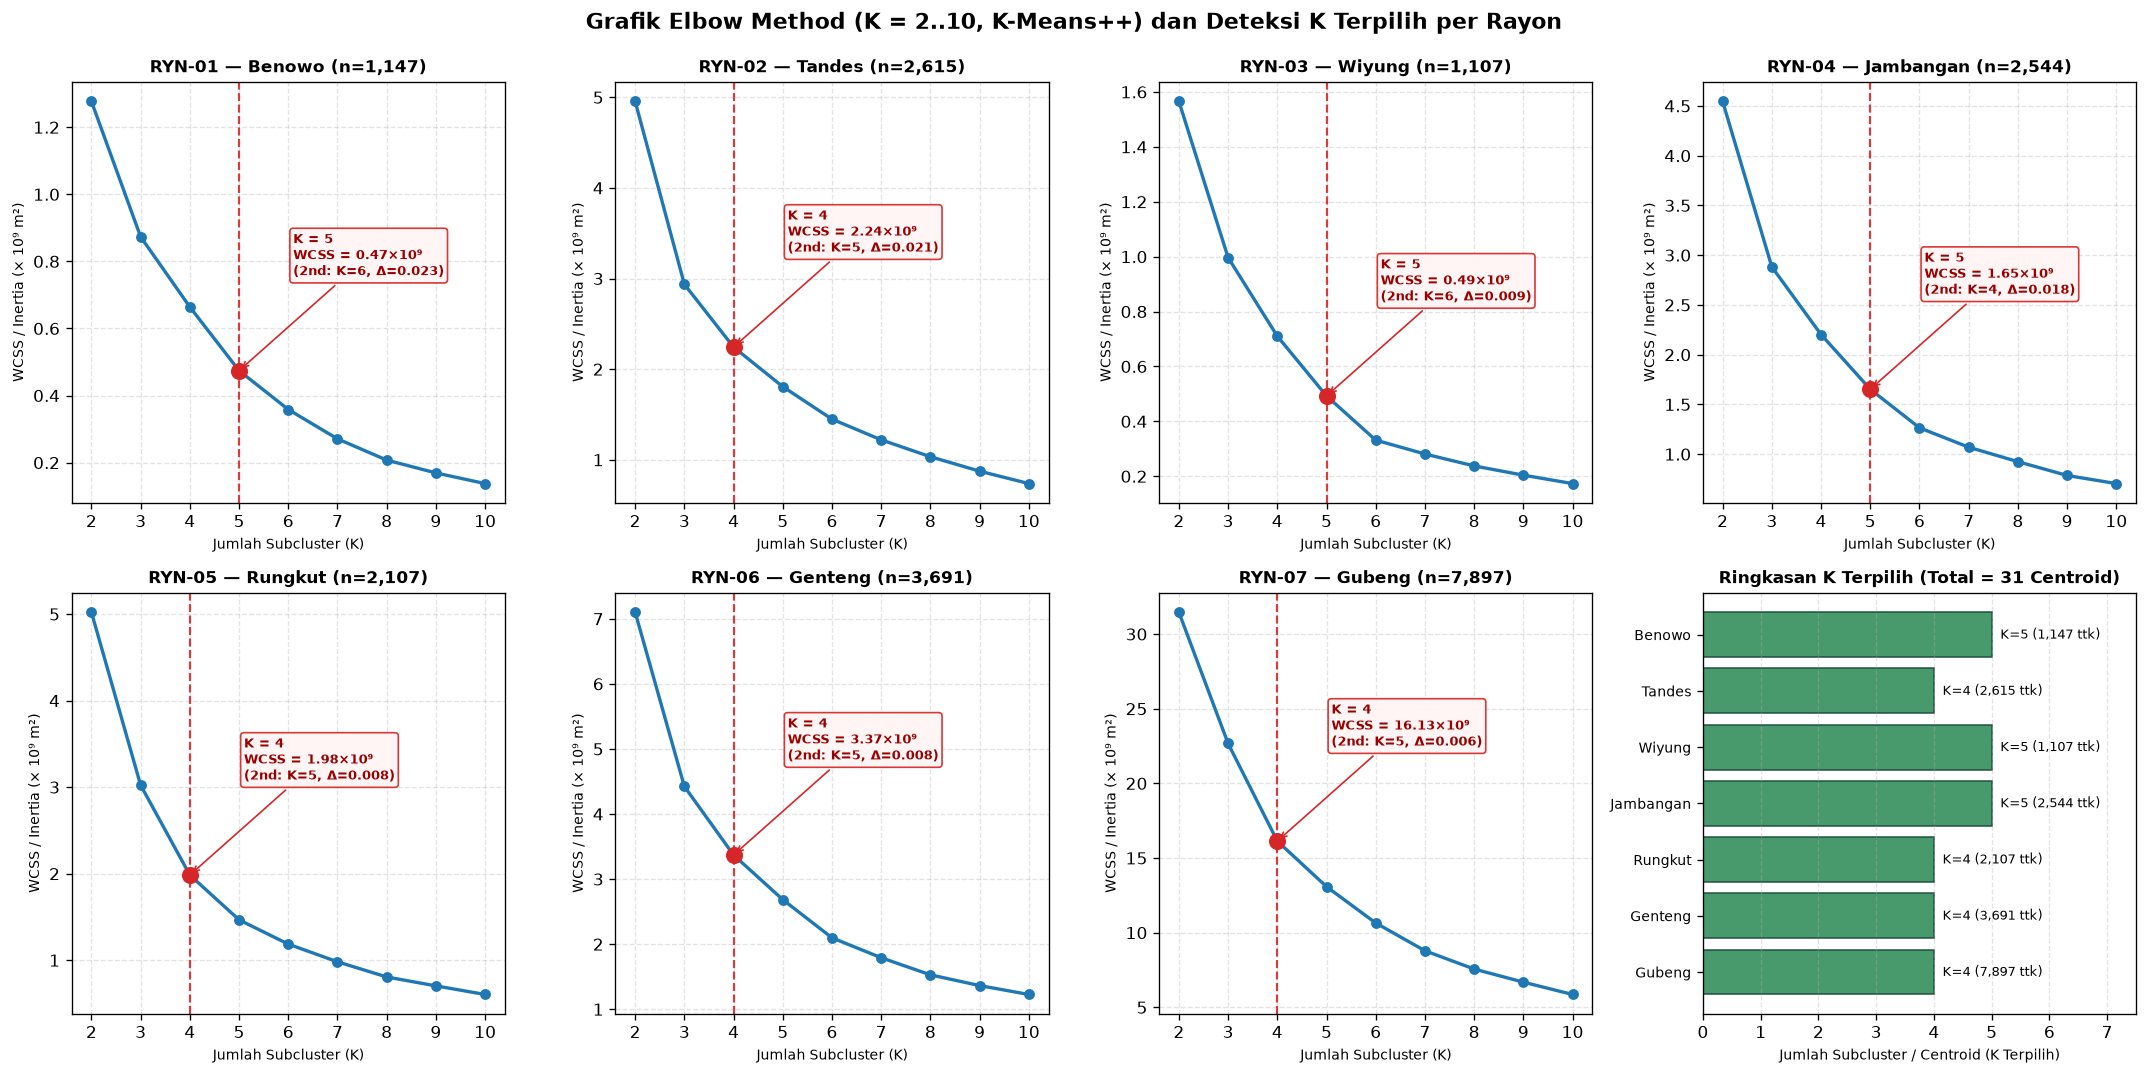

Grafik Elbow disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\04_elbow_method_7_rayon.png


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes_flat = axes.flatten()

rayon_names = gdf_rayon["nama_rayon"].tolist()

for idx, rname in enumerate(rayon_names):
    ax = axes_flat[idx]
    sub_e = df_elbow_all[df_elbow_all["nama_rayon"] == rname].sort_values("k")
    srow = df_kmeans_summary[df_kmeans_summary["nama_rayon"] == rname].iloc[0]
    k_sel = int(srow["k_digunakan"])
    w_sel = float(sub_e.loc[sub_e["k"] == k_sel, "wcss_1e9_m2"].iloc[0])

    ax.plot(sub_e["k"], sub_e["wcss_1e9_m2"], marker="o", color="#1F77B4", linewidth=2.0, markersize=5.5)
    ax.axvline(k_sel, color="#D62728", linestyle="--", linewidth=1.3, alpha=0.9)
    ax.scatter([k_sel], [w_sel], color="#D62728", s=85, zorder=5)

    # Anotasi K terpilih & runner-up
    ru = int(srow["runner_up_k"])
    mg = float(srow["kneedle_margin"])
    ax.annotate(
        f"K = {k_sel}\nWCSS = {w_sel:.2f}×10⁹\n(2nd: K={ru}, Δ={mg:.3f})",
        xy=(k_sel, w_sel),
        xytext=(min(k_sel + 1.1, 6.2), w_sel + (sub_e["wcss_1e9_m2"].max() - sub_e["wcss_1e9_m2"].min()) * 0.25),
        fontsize=8.0,
        fontweight="bold",
        color="#990000",
        bbox=dict(boxstyle="round,pad=0.25", fc="#FFF5F5", ec="#D62728", alpha=0.92),
        arrowprops=dict(arrowstyle="->", color="#D62728", lw=1.0),
    )

    ax.set_xticks(list(DEFAULT_K_RANGE))
    ax.set_title(f"{srow['id_rayon']} — {rname.replace('Rayon ', '')} (n={int(srow['jumlah_non_noise_input']):,})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Jumlah Subcluster (K)", fontsize=8.5)
    ax.set_ylabel("WCSS / Inertia (× 10⁹ m²)", fontsize=8.5)
    ax.grid(True, linestyle="--", alpha=0.35)

# Panel ke-8: Ringkasan Jumlah K Terpilih (Centroid Kandidat) per Rayon
ax_sum = axes_flat[7]
df_r = df_kmeans_summary[df_kmeans_summary["id_rayon"] != "TOTAL"].copy()
short_r = [n.replace("Rayon ", "") for n in df_r["nama_rayon"]]
y_pos = np.arange(len(short_r))

bars = ax_sum.barh(y_pos, df_r["k_digunakan"], color="#2E8B57", alpha=0.88, edgecolor="#1B4D3E")
ax_sum.set_yticks(y_pos)
ax_sum.set_yticklabels(short_r, fontsize=8.5)
ax_sum.invert_yaxis()
ax_sum.set_xlabel("Jumlah Subcluster / Centroid (K Terpilih)", fontsize=8.5)
ax_sum.set_title(f"Ringkasan K Terpilih (Total = {len(gdf_centroids)} Centroid)", fontsize=10, fontweight="bold")
ax_sum.set_xlim(0, max(df_r["k_digunakan"]) + 2.5)
ax_sum.grid(axis="x", linestyle="--", alpha=0.35)

for b, n_nn in zip(bars, df_r["jumlah_non_noise_input"]):
    w = b.get_width()
    ax_sum.text(w + 0.15, b.get_y() + b.get_height() / 2, f"K={int(w)} ({int(n_nn):,} ttk)", va="center", fontsize=8.0)

fig.suptitle("Grafik Elbow Method (K = 2..10, K-Means++) dan Deteksi K Terpilih per Rayon", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig_elbow_path = FIG_DIR / "04_elbow_method_7_rayon.png"
plt.savefig(fig_elbow_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Grafik Elbow disimpan ke: {fig_elbow_path}")

## 6. Visualisasi 2 & 3 — Peta Subcluster K-Means++ dan Centroid Kandidat Awal
- **Peta Kota Surabaya**: Menampilkan seluruh subcluster K-Means++, posisi **centroid kandidat awal** (simbol bintang kuning berbingkai hitam), serta titik **Noise DBSCAN** yang tetap dipertahankan (simbol silang merah).
- **Peta Detail per Rayon (Grid 2×4)**: Menampilkan pembagian subcluster pada masing-masing rayon lengkap dengan label `C1`, `C2`, ... pada tiap centroid.

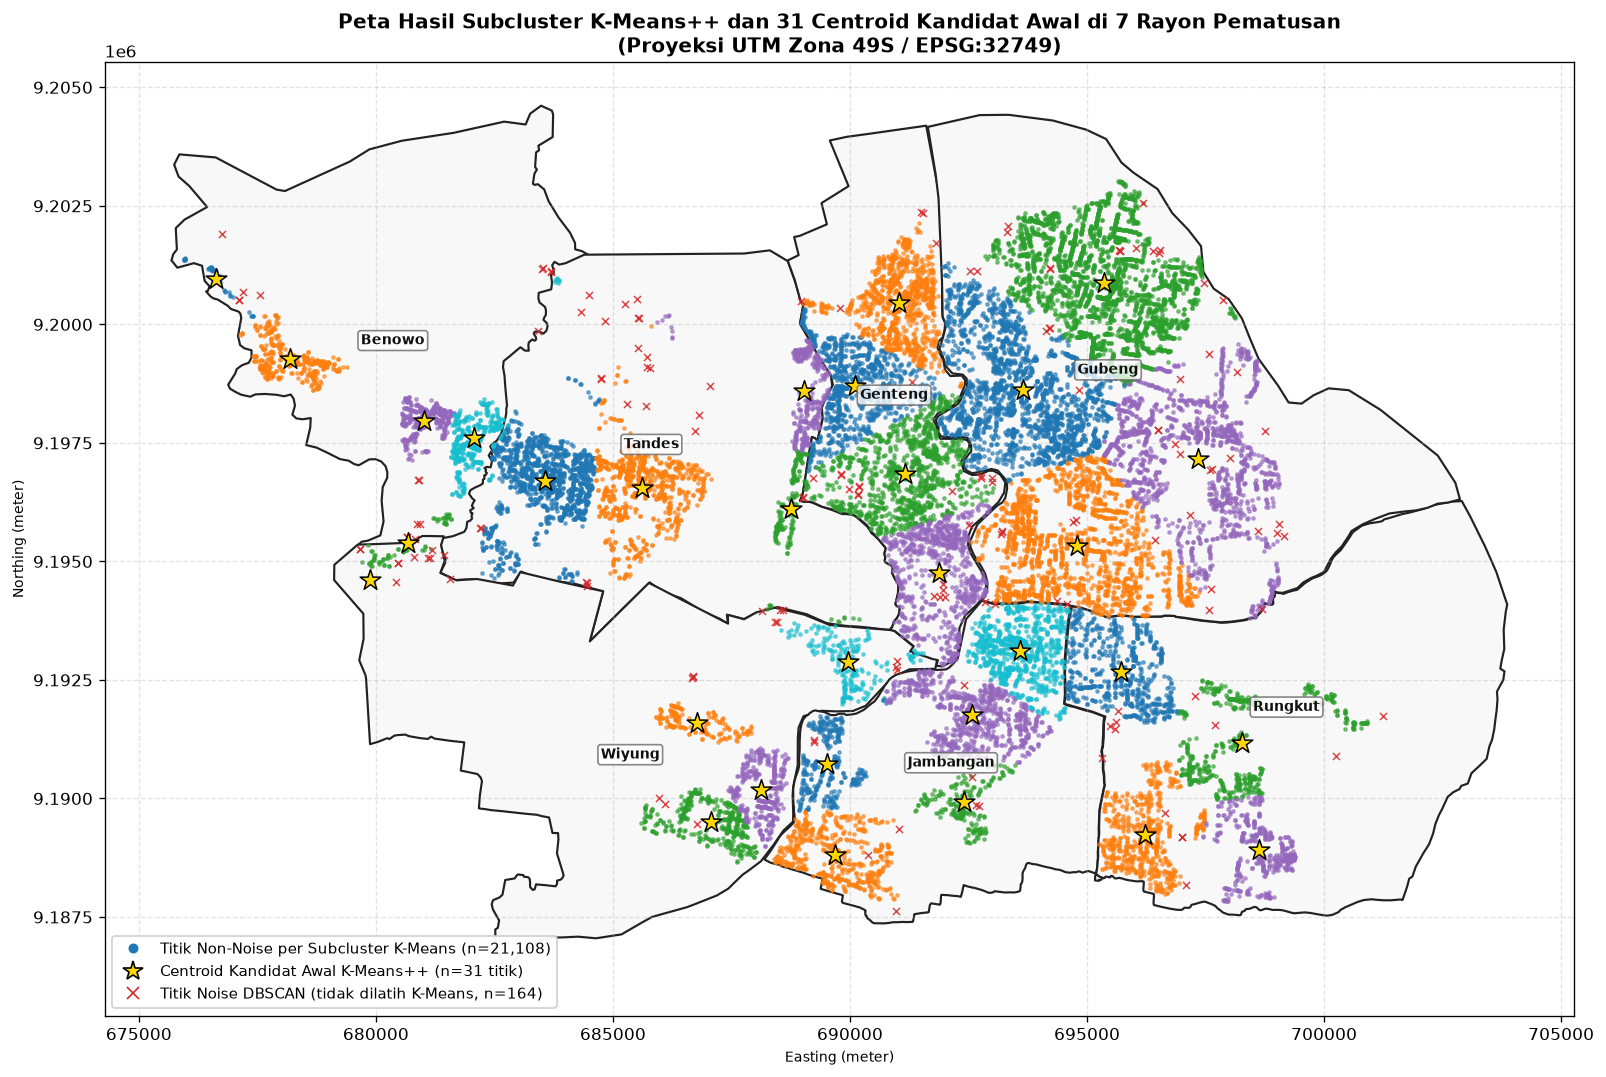

Peta Surabaya K-Means disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\04_peta_kmeans_surabaya.png


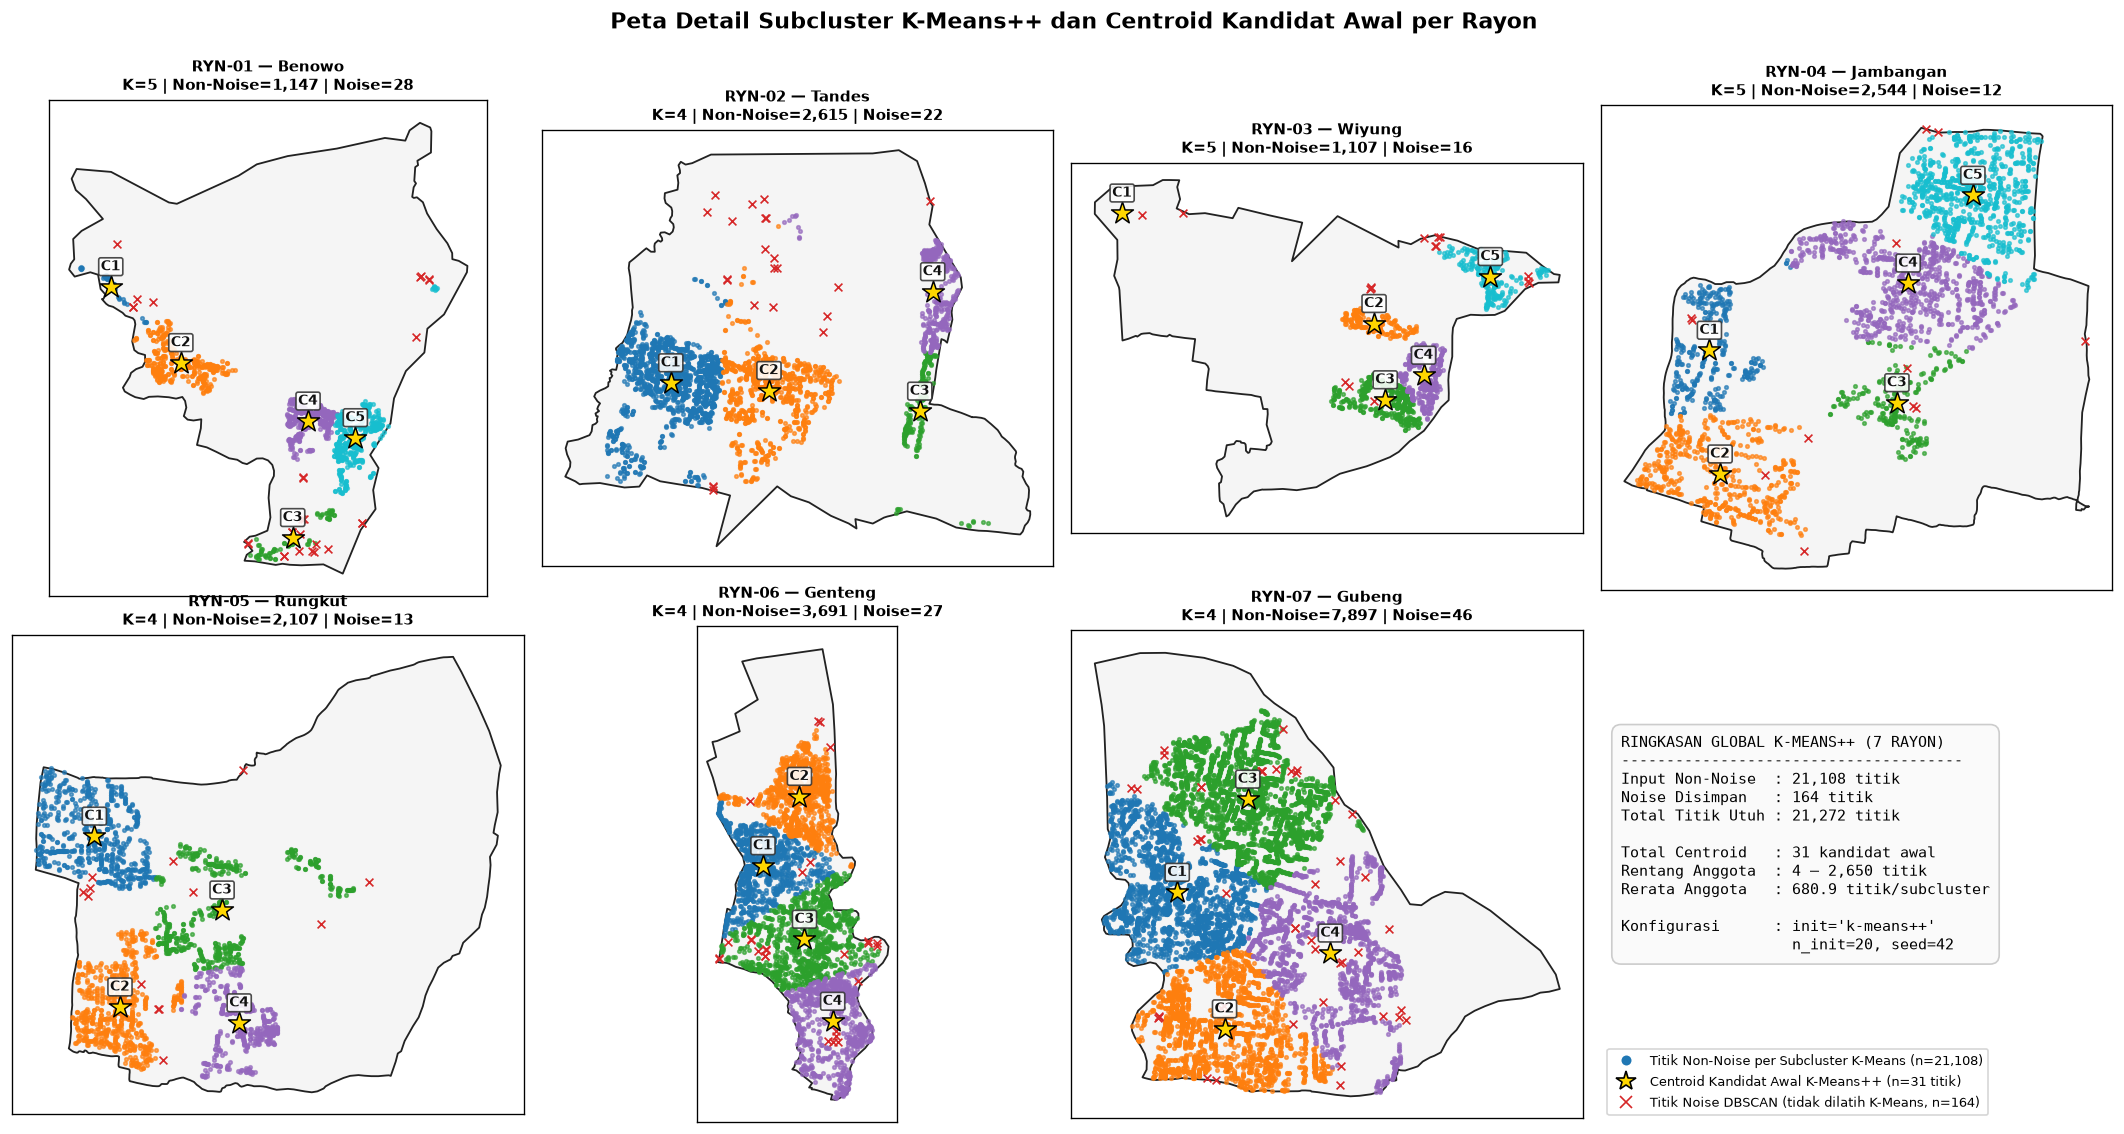

Peta detail per rayon K-Means disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\04_peta_kmeans_per_rayon.png


In [6]:
# Palet warna jelas untuk hingga 10 subcluster
PALETTE = [
    "#1F77B4", "#FF7F0E", "#2CA02C", "#9467BD", "#17BECF",
    "#E377C2", "#8C564B", "#BCBD22", "#393B79", "#AD494A"
]

# --- Peta Keseluruhan Kota Surabaya ---
fig, ax = plt.subplots(figsize=(13.5, 10))
gdf_rayon.plot(ax=ax, facecolor="#F8F8F8", edgecolor="#222222", linewidth=1.3, zorder=1)

# Plot titik Non-Noise per subcluster (menggunakan warna per indeks cluster 1..K)
for c_idx in sorted(gdf_kmeans.loc[gdf_kmeans["is_non_noise"], "kmeans_cluster"].unique()):
    sub_c = gdf_kmeans[gdf_kmeans["kmeans_cluster"] == c_idx]
    col = PALETTE[(int(c_idx) - 1) % len(PALETTE)]
    sub_c.plot(ax=ax, color=col, markersize=3.5, alpha=0.55, zorder=2)

# Plot titik Noise (tetap tampil!)
sub_noise_all = gdf_kmeans[~gdf_kmeans["is_non_noise"]]
sub_noise_all.plot(ax=ax, color="#D62728", marker="x", markersize=18, linewidth=0.9, alpha=0.85, zorder=4)

# Plot seluruh centroid kandidat awal
gdf_centroids.plot(
    ax=ax,
    color="#FFD700",
    edgecolor="black",
    marker="*",
    markersize=170,
    linewidth=0.9,
    zorder=6,
)

# Label nama rayon
for _, rrow in gdf_rayon.iterrows():
    pt = rrow.geometry.representative_point()
    ax.annotate(
        rrow["nama_rayon"].replace("Rayon ", ""),
        xy=(pt.x, pt.y),
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color="#111111",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#666666", alpha=0.78),
        zorder=7,
    )

handles_all = [
    Line2D([0], [0], marker="o", color="w", label=f"Titik Non-Noise per Subcluster K-Means (n={int(gdf_kmeans['is_non_noise'].sum()):,})", markerfacecolor="#1F77B4", markersize=7),
    Line2D([0], [0], marker="*", color="w", label=f"Centroid Kandidat Awal K-Means++ (n={len(gdf_centroids)} titik)", markerfacecolor="#FFD700", markeredgecolor="black", markersize=12),
    Line2D([0], [0], marker="x", color="#D62728", linestyle="None", label=f"Titik Noise DBSCAN (tidak dilatih K-Means, n={len(sub_noise_all)})", markersize=7),
]
ax.legend(handles=handles_all, loc="lower left", frameon=True, facecolor="white", framealpha=0.94, fontsize=9)
ax.set_title(f"Peta Hasil Subcluster K-Means++ dan {len(gdf_centroids)} Centroid Kandidat Awal di 7 Rayon Pematusan\n(Proyeksi UTM Zona 49S / EPSG:32749)", fontsize=12, fontweight="bold")
ax.set_xlabel("Easting (meter)")
ax.set_ylabel("Northing (meter)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_aspect("equal")

fig_km_all = FIG_DIR / "04_peta_kmeans_surabaya.png"
plt.tight_layout()
plt.savefig(fig_km_all, dpi=200, bbox_inches="tight")
plt.show()
print(f"Peta Surabaya K-Means disimpan ke: {fig_km_all}")

# --- Peta Detail per Rayon (Grid 2x4) ---
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
axes_flat = axes.flatten()

for idx, (_, rrow) in enumerate(gdf_rayon.iterrows()):
    ax = axes_flat[idx]
    rname = rrow["nama_rayon"]
    rid = rrow["id_rayon"]
    sub = gdf_kmeans[gdf_kmeans["nama_rayon"] == rname]
    sub_cen = gdf_centroids[gdf_centroids["nama_rayon"] == rname].sort_values("kmeans_cluster")
    srow = df_kmeans_summary[df_kmeans_summary["nama_rayon"] == rname].iloc[0]

    gpd.GeoSeries([rrow.geometry], crs=gdf_rayon.crs).plot(
        ax=ax, facecolor="#F5F5F5", edgecolor="#222222", linewidth=1.1, zorder=1
    )

    # Subcluster K-Means
    for c_idx in sorted(sub.loc[sub["is_non_noise"], "kmeans_cluster"].unique()):
        sc = sub[sub["kmeans_cluster"] == c_idx]
        col = PALETTE[(int(c_idx) - 1) % len(PALETTE)]
        sc.plot(ax=ax, color=col, markersize=4.5, alpha=0.65, zorder=2)

    # Noise DBSCAN
    sn = sub[~sub["is_non_noise"]]
    if len(sn) > 0:
        sn.plot(ax=ax, color="#D62728", marker="x", markersize=22, linewidth=1.0, zorder=4)

    # Centroid + Label C1..CK
    sub_cen.plot(ax=ax, color="#FFD700", edgecolor="black", marker="*", markersize=190, linewidth=0.9, zorder=6)
    for _, crow in sub_cen.iterrows():
        ax.annotate(
            f"C{int(crow['kmeans_cluster'])}",
            xy=(crow["easting"], crow["northing"]),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.2,
            fontweight="bold",
            color="#111111",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="#333333", alpha=0.88),
            zorder=7,
        )

    ax.set_title(
        f"{rid} — {rname.replace('Rayon ', '')}\nK={int(srow['k_digunakan'])} | Non-Noise={int(srow['jumlah_non_noise_input']):,} | Noise={int(srow['jumlah_noise_tidak_dilatih'])}",
        fontsize=9.2,
        fontweight="bold",
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect("equal")

# Panel ke-8: Ringkasan Global
ax_leg = axes_flat[7]
ax_leg.axis("off")
tot = df_kmeans_summary[df_kmeans_summary["id_rayon"] == "TOTAL"].iloc[0]
info_txt = (
    "RINGKASAN GLOBAL K-MEANS++ (7 RAYON)\n"
    "--------------------------------------\n"
    f"Input Non-Noise  : {int(tot['jumlah_non_noise_input']):,} titik\n"
    f"Noise Disimpan   : {int(tot['jumlah_noise_tidak_dilatih']):,} titik\n"
    f"Total Titik Utuh : {int(tot['jumlah_total_titik']):,} titik\n\n"
    f"Total Centroid   : {len(gdf_centroids)} kandidat awal\n"
    f"Rentang Anggota  : {int(tot['min_anggota_subcluster'])} – {int(tot['max_anggota_subcluster']):,} titik\n"
    f"Rerata Anggota   : {tot['rerata_anggota_subcluster']:.1f} titik/subcluster\n\n"
    "Konfigurasi      : init='k-means++'\n"
    f"                   n_init={DEFAULT_KMEANS_N_INIT}, seed={DEFAULT_RANDOM_STATE}"
)
ax_leg.text(0.04, 0.56, info_txt, va="center", ha="left", fontsize=9.2, family="monospace",
            bbox=dict(boxstyle="round,pad=0.6", fc="#FAFAFA", ec="#CCCCCC"))
ax_leg.legend(handles=handles_all, loc="lower left", frameon=True, fontsize=8.0)

fig.suptitle("Peta Detail Subcluster K-Means++ dan Centroid Kandidat Awal per Rayon", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig_km_rayon = FIG_DIR / "04_peta_kmeans_per_rayon.png"
plt.savefig(fig_km_rayon, dpi=200, bbox_inches="tight")
plt.show()
print(f"Peta detail per rayon K-Means disimpan ke: {fig_km_rayon}")

## 7. Validasi Akhir & Penyimpanan Output Tahap 4
Memastikan seluruh *assertion* metodologis terpenuhi (titik utuh `21.272`, seluruh Noise berlabel `-1`, seluruh Non-Noise berlabel `1..K`, CRS seragam `EPSG:32749`, dan koordinat balik WGS84 valid), lalu menyimpan ke `data/processed/` dan `outputs/tables/`.

In [7]:
# Validasi otomatis Tahap 4
assert len(gdf_kmeans) == len(gdf_dbscan), "Jumlah titik berubah!"
assert int((gdf_kmeans["kmeans_cluster"] == -1).sum()) == int((~gdf_dbscan["is_non_noise"]).sum())
assert (gdf_kmeans.loc[gdf_kmeans["is_non_noise"], "kmeans_cluster"] >= 1).all()
assert gdf_kmeans.crs.to_epsg() == 32749
assert gdf_centroids.crs.to_epsg() == 32749
assert gdf_centroids["longitude"].between(112.5, 112.9).all()
assert gdf_centroids["latitude"].between(-7.4, -7.1).all()
assert int(gdf_centroids["jumlah_titik"].sum()) == int(gdf_kmeans["is_non_noise"].sum())

saved = save_kmeans_outputs(
    processed_dir=PROCESSED_DIR,
    tables_dir=TAB_DIR,
    gdf_kmeans=gdf_kmeans,
    gdf_centroids=gdf_centroids,
    df_elbow_all=df_elbow_all,
    df_summary=df_kmeans_summary,
)

print("VALIDASI TAHAP 4 LULUS SEMUA ASSERTION!")
print("File keluaran berhasil disimpan:")
for k, p in saved.items():
    print(f"  - {k:28s}: {p.relative_to(PROJECT_ROOT)} ({p.stat().st_size:,} bytes)")

VALIDASI TAHAP 4 LULUS SEMUA ASSERTION!
File keluaran berhasil disimpan:
  - saluran_kmeans_gpkg         : data\processed\saluran_kmeans_utm49s.gpkg (7,966,720 bytes)
  - saluran_kmeans_csv          : data\processed\saluran_kmeans_utm49s.csv (6,369,008 bytes)
  - centroid_kmeans_gpkg        : data\processed\centroid_kmeans_utm49s.gpkg (106,496 bytes)
  - centroid_kmeans_csv         : data\processed\centroid_kmeans_utm49s.csv (3,753 bytes)
  - elbow_wcss_csv              : outputs\tables\04_kmeans_elbow_wcss_7_rayon.csv (5,320 bytes)
  - kmeans_ringkasan_csv        : outputs\tables\04_kmeans_ringkasan_per_rayon.csv (1,501 bytes)
  - centroid_kandidat_table_csv : outputs\tables\04_kmeans_centroid_kandidat.csv (3,753 bytes)
